<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Layers  Filter Size Pooling  Batch Norm  Learning Rate  Batch Size  Accuracy  Parameters  Training Time
      2            3     max       False         0.0010          32  0.925000      136586           7.81
      3            3     max        True         0.0010          32  0.177778       68922           5.64
      4            3 average        True         0.0005          64  0.083333       64122           7.23
      2            5 average       False         0.0010          64  0.927778      145034           5.13
      3            5     max        True         0.0005          32  0.100000      101946          10.08


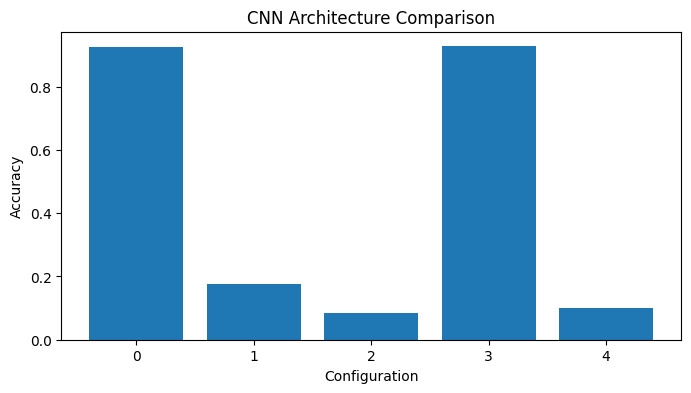

In [7]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

# Load small dataset
digits = load_digits()
X = digits.images[..., np.newaxis]
y = digits.target
X = tf.image.resize(X, (32, 32)).numpy() / 16.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

def build_model(layers, kernel, pooling, batch_norm, lr):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(32, 32, 1)))

    for i in range(layers):
        model.add(tf.keras.layers.Conv2D(
            16 * (i + 1), kernel, padding='same', activation='relu'
        ))
        if batch_norm:
            model.add(tf.keras.layers.BatchNormalization())

        if pooling == 'max':
            model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2)))
        else:
            model.add(tf.keras.layers.AveragePooling2D(pool_size=(2, 2)))

    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(64, activation='relu'))
    model.add(tf.keras.layers.Dense(10, activation='softmax'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

configs = [
    (2, 3, 'max', False, 0.001, 32),
    (3, 3, 'max', True, 0.001, 32),
    (4, 3, 'average', True, 0.0005, 64),
    (2, 5, 'average', False, 0.001, 64),
    (3, 5, 'max', True, 0.0005, 32)
]

results = []

for layers, kernel, pool, bn, lr, batch in configs:
    model = build_model(layers, kernel, pool, bn, lr)
    start = time.time()

    model.fit(X_train, y_train, epochs=2,
              batch_size=batch, verbose=0)

    elapsed = time.time() - start
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    results.append([
        layers, kernel, pool, bn, lr, batch,
        accuracy, model.count_params(), round(elapsed, 2)
    ])

df = pd.DataFrame(results, columns=[
    'Layers', 'Filter Size', 'Pooling', 'Batch Norm',
    'Learning Rate', 'Batch Size', 'Accuracy',
    'Parameters', 'Training Time'
])

print(df.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.bar(range(len(df)), df['Accuracy'])
plt.xlabel("Configuration")
plt.ylabel("Accuracy")
plt.title("CNN Architecture Comparison")
plt.show()